In [1]:

# WSN Malicious Event Detection using Machine Learning

# Step 1: Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Step 2: Load dataset
df = pd.read_csv("WSN_Dataset.csv")

print("Dataset Shape:", df.shape)
print("\nDataset Columns:")
print(df.columns.tolist())

print("\nDataset Preview:")
print(df.head())

# Step 3: Configure actual dataset column names
FEATURES = [
    "Context",
    "Timestamp",
    "Source IP",
    "Event Type"
]

TARGET = "Label"  # Replace with actual target column

# Step 4: Validate columns
required = FEATURES + [TARGET]

missing = [col for col in required if col not in df.columns]

if missing:
    raise ValueError(
        f"Update FEATURES and TARGET. Missing columns: {missing}"
    )

# Step 5: Data preprocessing
df = df[required].copy()
df = df.drop_duplicates()
df = df.dropna(subset=[TARGET])

# Handle missing feature values
for col in FEATURES:
    if df[col].dtype == "object":
        df[col] = df[col].fillna("Unknown")
    else:
        df[col] = df[col].fillna(df[col].median())

# Step 6: Feature engineering
# Convert timestamp into useful numerical features
timestamp = pd.to_datetime(
    df["Timestamp"], errors="coerce"
)

df["Hour"] = timestamp.dt.hour
df["Day"] = timestamp.dt.dayofweek

df["Hour"] = df["Hour"].fillna(-1)
df["Day"] = df["Day"].fillna(-1)

# Remove original timestamp
df = df.drop(columns=["Timestamp"])

# Step 7: Encode categorical features
X = df.drop(columns=[TARGET])
y = df[TARGET].astype(str)

encoders = {}

for col in X.columns:
    if X[col].dtype == "object":
        encoder = LabelEncoder()
        X[col] = encoder.fit_transform(X[col].astype(str))
        encoders[col] = encoder

target_encoder = LabelEncoder()
y = target_encoder.fit_transform(y)

print("\nClass Distribution:")
print(pd.Series(y).value_counts())

# Step 8: Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Step 9: Train Random Forest model
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

model.fit(X_train, y_train)

# Step 10: Predict
y_pred = model.predict(X_test)

# Step 11: Evaluate model
accuracy = accuracy_score(y_test, y_pred)

print("\nMODEL RESULTS")
print("-----------------------")
print("Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=target_encoder.classes_.astype(str),
    zero_division=0
))

# Step 12: Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=target_encoder.classes_
)

display.plot(cmap="Blues")
plt.title("WSN Malicious Event Detection")
plt.tight_layout()
plt.show()

# Step 13: Feature Importance
importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("\nFeature Importance:")
print(importance)

importance.plot(kind="bar")
plt.title("Feature Importance in WSN Intrusion Detection")
plt.ylabel("Importance")
plt.tight_layout()
plt.show()

# Step 14: Save trained model
import joblib

joblib.dump(
    {
        "model": model,
        "encoders": encoders,
        "target_encoder": target_encoder,
        "features": list(X.columns)
    },
    "wsn_intrusion_model.pkl"
)

print("\nModel saved successfully!")


Dataset Shape: (10000, 18)

Dataset Columns:
['Node_ID', 'Timestamp', 'X_Coordinate', 'Y_Coordinate', 'Z_Coordinate', 'Initial_Energy', 'Residual_Energy', 'Transmission_Power', 'Signal_Strength', 'Noise_Level', 'Energy_Consumption', 'Packet_Loss_Rate', 'Network_Lifetime', 'Optimization_Algorithm', 'Adaptive_Learning_Rate', 'Temperature', 'Humidity', 'Detection_Accuracy']

Dataset Preview:
   Node_ID            Timestamp  X_Coordinate  Y_Coordinate  Z_Coordinate  \
0        1  2024-01-01 00:00:00     37.454012     37.364082     36.499916   
1        2  2024-01-01 00:01:00     95.071431     33.291210      9.225600   
2        3  2024-01-01 00:02:00     73.199394     17.615391     17.331985   
3        4  2024-01-01 00:03:00     59.865848     60.726667     33.164032   
4        5  2024-01-01 00:04:00     15.601864     47.662416     24.104467   

   Initial_Energy  Residual_Energy  Transmission_Power  Signal_Strength  \
0       11.381446         2.989120            2.133368       -45.50668

ValueError: Update FEATURES and TARGET. Missing columns: ['Context', 'Source IP', 'Event Type', 'Label']

Dataset Shape: (10000, 18)

Dataset Preview:
   Node_ID            Timestamp  X_Coordinate  Y_Coordinate  Z_Coordinate  \
0        1  2024-01-01 00:00:00     37.454012     37.364082     36.499916   
1        2  2024-01-01 00:01:00     95.071431     33.291210      9.225600   
2        3  2024-01-01 00:02:00     73.199394     17.615391     17.331985   
3        4  2024-01-01 00:03:00     59.865848     60.726667     33.164032   
4        5  2024-01-01 00:04:00     15.601864     47.662416     24.104467   

   Initial_Energy  Residual_Energy  Transmission_Power  Signal_Strength  \
0       11.381446         2.989120            2.133368       -45.506688   
1        9.592925         0.948178            1.286841       -37.133887   
2       14.644985         1.263592            0.569117       -62.209207   
3        7.189785         1.806711            1.867940       -72.649276   
4       10.878564         2.036533            1.104828       -70.869206   

   Noise_Level  Energy_Consumption  Packe

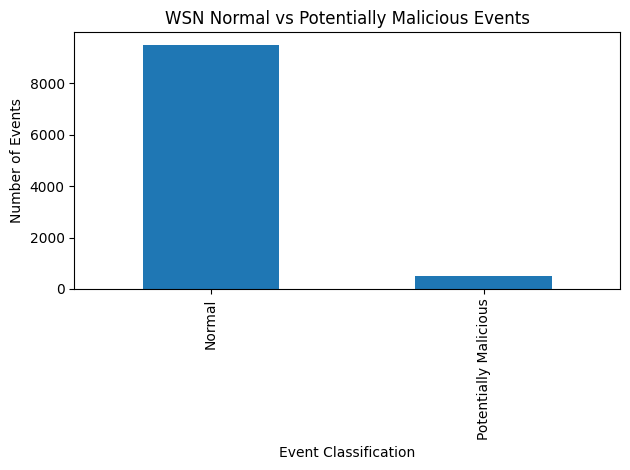


Model and detection results saved successfully!


In [3]:

# WSN Malicious Event Detection using Isolation Forest

# Step 1: Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

# Step 2: Load dataset
df = pd.read_csv("WSN_Dataset.csv")

print("Dataset Shape:", df.shape)
print("\nDataset Preview:")
print(df.head())

# Step 3: Data preprocessing
df = df.drop_duplicates().copy()

# Handle missing values
df = df.dropna(subset=["Timestamp"])

# Convert timestamp
df["Timestamp"] = pd.to_datetime(
    df["Timestamp"], errors="coerce"
)

df = df.dropna(subset=["Timestamp"])

# Extract time-based features
df["Hour"] = df["Timestamp"].dt.hour
df["Day"] = df["Timestamp"].dt.dayofweek

# Step 4: Select relevant features
features = [
    "X_Coordinate",
    "Y_Coordinate",
    "Z_Coordinate",
    "Initial_Energy",
    "Residual_Energy",
    "Transmission_Power",
    "Signal_Strength",
    "Noise_Level",
    "Energy_Consumption",
    "Packet_Loss_Rate",
    "Network_Lifetime",
    "Adaptive_Learning_Rate",
    "Temperature",
    "Humidity",
    "Hour",
    "Day"
]

X = df[features].copy()

# Handle missing numerical values
X = X.fillna(X.median())

# Step 5: Feature scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Step 6: Build Isolation Forest model
model = IsolationForest(
    n_estimators=100,
    contamination=0.05,
    random_state=42
)

model.fit(X_scaled)

# Step 7: Detect anomalies
predictions = model.predict(X_scaled)

df["Detection_Result"] = np.where(
    predictions == -1,
    "Potentially Malicious",
    "Normal"
)

# Step 8: Display results
print("\nWSN INTRUSION DETECTION RESULTS")
print("--------------------------------")

print(df["Detection_Result"].value_counts())

print("\nFirst 10 Predictions:")
print(df[["Node_ID", "Timestamp",
          "Detection_Result"]].head(10))

# Step 9: Calculate detection percentage
anomalies = (predictions == -1).sum()
total = len(predictions)

print("\nTotal Events:", total)
print("Potential Anomalies:", anomalies)
print("Normal Events:", total - anomalies)

print("Anomaly Percentage:",
      round((anomalies / total) * 100, 2), "%")

# Step 10: Visualize results
df["Detection_Result"].value_counts().plot(
    kind="bar"
)

plt.title("WSN Normal vs Potentially Malicious Events")
plt.xlabel("Event Classification")
plt.ylabel("Number of Events")
plt.tight_layout()
plt.show()

# Step 11: Save results
df.to_csv("WSN_Detection_Results.csv", index=False)

import joblib

joblib.dump(
    {"model": model, "scaler": scaler, "features": features},
    "WSN_Intrusion_Model.pkl"
)

print("\nModel and detection results saved successfully!")
